# compare photo-$z$s
Compare the saved predictions from `broadband_flow.ipynb`, `bootstrapped_flow.ipynb`,
and `noisesom.ipynb` with the released LePhare PDFs in `data/parent.npz`.
Run those notebooks first, then run this notebook from `nb/` with the project kernel.

The flows augment training noise; NoiseSOM uses fixed degraded photometry.
The bootstrapped flow uses more galaxies and probabilistic labels supplied by
LePhare, which uses deep multiband data. The methods therefore use different
training information. Accuracy and coverage refer to the spectroscopic test sample.

In [1]:
import numpy as np
from pzflow.utils import PDFSampler, coverage

In [2]:
import matplotlib as mpl
import matplotlib.pyplot as plt
mpl.rcParams['text.usetex'] = True
mpl.rcParams['font.family'] = 'serif'
mpl.rcParams['axes.linewidth'] = 1.5
mpl.rcParams['axes.xmargin'] = 1
mpl.rcParams['xtick.labelsize'] = 'x-large'
mpl.rcParams['xtick.major.size'] = 5
mpl.rcParams['xtick.major.width'] = 1.5
mpl.rcParams['ytick.labelsize'] = 'x-large'
mpl.rcParams['ytick.major.size'] = 5
mpl.rcParams['ytick.major.width'] = 1.5
mpl.rcParams['legend.frameon'] = False

## 1. Set comparison inputs

In [17]:
inputs = {
    'broadband': '../data/broadband_flow_test_predictions.npz',
    'bootstrapped': '../data/bootstrapped_flow_test_predictions.npz',
    'noisesom': '../data/noisesom_test_predictions.npz',
}
#out_dir = Path('../results/paper_comparison')
#paper_dir = Path('../tex/figures')
#export_paper = True

bootstrap_draws = 200
bootstrap_seed = 20261124
magnitude_edges = np.array([-np.inf, 22.5, 24.0, 24.5, 25.0])

models = [
    ('bootstrapped', 'COSMOS Bootstrapped flow', 'C0'),
    ('broadband', 'Broadband flow', 'C1'),
    ('noisesom', 'Broadband NoiseSOM', 'C2'),
    ('lephare', 'COSMOS LePhare', 'C3'),
]
#out_dir.mkdir(parents=True, exist_ok=True)
#if export_paper:
#    paper_dir.mkdir(parents=True, exist_ok=True)

## 2. Load and align test predictions
Use every secure spectroscopic galaxy in parent split 2. Match predictions by ID
and check their redshifts, magnitudes, fluxes, and errors against the parent.
The current output files share `quantiles`, `pit`, and `nll` fields; no run manifest
is required. These checks verify the saved test rows, not the training provenance.

In [5]:
def align_prediction(path, target_ids):
    with np.load(path) as f:
        source_ids = f['id']
        if len(np.unique(source_ids)) != len(source_ids):
            raise ValueError(f'Duplicate IDs in {path}')
        order = np.argsort(source_ids)
        sorted_ids = source_ids[order]
        j = np.searchsorted(sorted_ids, target_ids)
        if np.any(j == len(sorted_ids)) or not np.array_equal(sorted_ids[j], target_ids):
            raise ValueError(f'Missing test galaxies in {path}')
        rows = order[j]
        keys = ['id', 'zspec', 'imag', 'flux', 'fluxerr', 'quantiles', 'pit', 'nll']
        return {key: f[key][rows] for key in keys}


with np.load('../data/parent.npz') as parent:
    assert len(np.unique(parent['id'])) == len(parent['id'])
    test = np.flatnonzero((parent['split'] == 2) & parent['has_specz'])
    truth = {key: parent[key][test] for key in ['id', 'zspec', 'imag', 'flux', 'fluxerr']}
    lephare_grid = parent['grid']
    lephare_pdf = parent['pdf'][test]
assert len(test) and np.isfinite(truth['zspec']).all()

predictions = {}
for key, path in inputs.items():
    saved = align_prediction(path, truth['id'])
    for field in ['zspec', 'imag', 'flux', 'fluxerr']:
        if not np.array_equal(saved[field], truth[field]):
            raise ValueError(f'{key}: mismatched {field}')
    predictions[key] = {field: saved[field] for field in ['quantiles', 'pit']}
print(f'Comparing {len(test):,} spectroscopic test galaxies')

Comparing 5,083 spectroscopic test galaxies


## 3. Calculate LePhare quantiles and PIT
Normalize the released PDFs and invert the integrated piecewise-linear density.
Use posterior medians for all four methods, without correcting the LePhare prior.

In [6]:
def pdf_quantiles(sampler, probs=(0.025, 0.16, 0.5, 0.84, 0.975)):
    rows = np.arange(len(sampler.p))
    columns = []
    for prob in probs:
        # Locate the CDF cell, then solve its integrated linear density exactly.
        j = np.clip((sampler.c <= prob).sum(axis=1) - 1, 0, len(sampler.grid) - 2)
        width = np.diff(sampler.grid)[j]
        a = sampler.p[rows, j]
        slope = (sampler.p[rows, j + 1] - a) / width
        mass = np.maximum(prob - sampler.c[rows, j], 0)
        den = a + np.sqrt(np.maximum(a * a + 2 * slope * mass, 0))
        step = np.divide(2 * mass, den, out=np.zeros_like(mass), where=den > 0)
        columns.append(sampler.grid[j] + np.clip(step, 0, width))
    return np.column_stack(columns)


sampler = PDFSampler(lephare_grid, lephare_pdf)
predictions['lephare'] = {'quantiles': pdf_quantiles(sampler), 'pit': sampler.pit(truth['zspec'])}
del sampler, lephare_pdf
for key, pred in predictions.items():
    q, pit = pred['quantiles'], pred['pit']
    assert q.shape == (len(test), 5) and pit.shape == (len(test),)
    assert np.isfinite(q).all() and np.isfinite(pit).all()
    assert np.all(np.diff(q, axis=1) >= 0) and np.all((pit >= 0) & (pit <= 1))

## 4. Compare accuracy and interval coverage

In [7]:
def summarize(z, q, pit):
    residual = (q[:, 2] - z) / (1 + z)
    c68, c95 = coverage(pit)
    return {
        'n': len(z),
        'bias': float(np.median(residual)),
        'nmad': float(1.4826 * np.median(abs(residual - np.median(residual)))),
        'outlier_fraction': float(np.mean(abs(residual) > 0.15)),
        'coverage68': float(c68),
        'coverage95': float(c95),
        'median_width68': float(np.median(q[:, 3] - q[:, 1])),
    }


z = truth['zspec']
summary = {key: summarize(z, pred['quantiles'], pred['pit']) for key, pred in predictions.items()}
print(f'{"Method":28s} {"NMAD":>8s} {"Outliers":>10s} {"C68":>8s} {"C95":>8s}')
for key, label, _ in models:
    m = summary[key]
    print(
        f'{label:28s} {m["nmad"]:8.4f} {100 * m["outlier_fraction"]:9.2f}% '
        f'{100 * m["coverage68"]:7.1f}% {100 * m["coverage95"]:7.1f}%'
    )

Method                           NMAD   Outliers      C68      C95
Broadband flow                 0.0184      2.95%    65.1%    93.9%
COSMOS Bootstrapped flow       0.0178      2.60%    69.8%    94.6%
NoiseSOM                       0.0280      5.02%    79.2%    97.7%
COSMOS LePhare                 0.0100      2.30%    56.3%    82.0%


## 5. Compare scatter versus magnitude
Use bins $i<22.5$, $22.5\leq i <24$, $24 \leq i < 24.5$, and $24.5 \leq i<25$, with points at their actual median magnitudes. 
Use the same 200 galaxy-bootstrap draws for all methods.

In [13]:
mag = truth['imag']
rng = np.random.default_rng(bootstrap_seed)
centers, counts = [], []
binned = {key: [] for key, _, _ in models}
limits = {key: [] for key, _, _ in models}
for lo, hi in zip(magnitude_edges[:-1], magnitude_edges[1:]):
    idx = np.flatnonzero((mag >= lo) & (mag < hi))
    if not len(idx):
        raise ValueError(f'Empty magnitude bin [{lo}, {hi})')
    centers.append(float(np.median(mag[idx])))
    counts.append(len(idx))
    draws = rng.choice(idx, size=(bootstrap_draws, len(idx)), replace=True)
    for key, _, _ in models:
        q, pit = predictions[key]['quantiles'], predictions[key]['pit']
        binned[key].append(summarize(z[idx], q[idx], pit[idx]))
        scatter = [summarize(z[d], q[d], pit[d])['nmad'] for d in draws]
        limits[key].append(np.quantile(scatter, [0.16, 0.84])) #[0.025, 0.975]))
assert sum(counts) == np.count_nonzero(mag < magnitude_edges[-1])

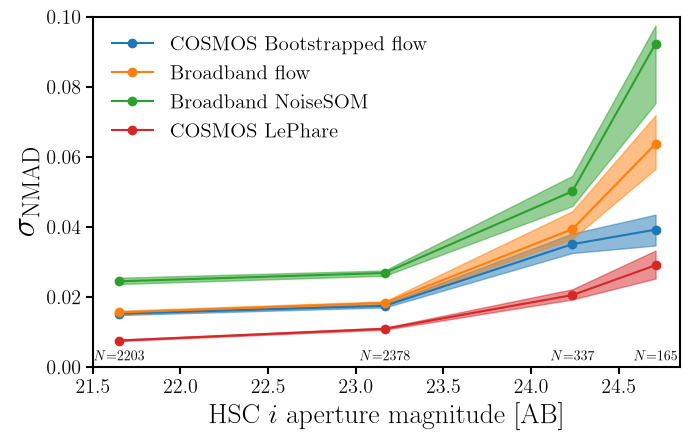

In [26]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for key, label, color in models:
    value = np.array([m['nmad'] for m in binned[key]])
    band = np.array(limits[key])
    ax.plot(centers, value, 'o-', color=color, label=label)
    ax.fill_between(centers, band[:, 0], band[:, 1], color=color, alpha=0.5)
    
for x, count in zip(centers, counts):
    ax.text(x, 0.02, f'$N$={count}', transform=ax.get_xaxis_transform(), ha='center', fontsize=10)
ax.set_xlabel('HSC $i$ aperture magnitude [AB]', fontsize=20)
ax.set_xlim(21.5, 24.85)
ax.set_ylim(0., 0.1)
ax.set_ylabel(r'$\sigma_{\rm NMAD}$', fontsize=25)
ax.legend(fontsize=15)
fig.tight_layout()
#fig.savefig(out_dir / 'magnitude.png', dpi=180)
#if export_paper:
#    fig.savefig(paper_dir / 'fig04_magnitude_dependence_notebook_comparison.pdf')
#print('Bin counts:', counts)
#print('Effective magnitudes:', centers)
plt.show()

## 6. Compare redshift accuracy and calibration

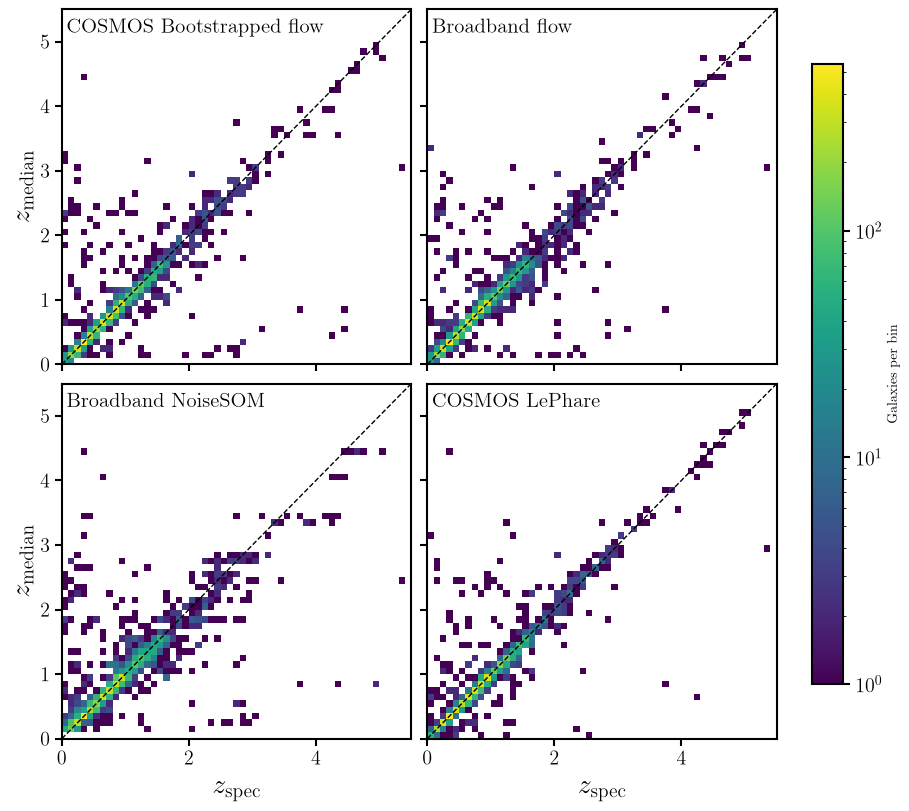

In [34]:
from matplotlib.colors import LogNorm

bins = np.linspace(0, 6, 61)
vmax = max(
    np.histogram2d(z, predictions[key]['quantiles'][:, 2], bins=[bins, bins])[0].max()
    for key, _, _ in models
)
norm = LogNorm(vmin=1, vmax=max(2, vmax))

fig, axes = plt.subplots(
    2, 2, figsize=(9, 8), sharex=True, sharey=True, constrained_layout=True
)
for ax, (key, label, _) in zip(axes.flat, models):
    _, _, _, im = ax.hist2d(
        z, predictions[key]['quantiles'][:, 2],
        bins=[bins, bins], cmap='viridis', norm=norm, cmin=1,
        rasterized=True,
    )
    ax.plot([0, 6], [0, 6], 'k--', lw=1)
    ax.set(xlim=(0, 5.5), ylim=(0, 5.5))
    ax.text(0.075, 0.975, label, transform=ax.get_xaxis_transform(), ha='left', va='top', fontsize=15)

for ax in axes[-1]:
    ax.set_xlabel(r'$z_{\rm spec}$', fontsize=20)
for ax in axes[:, 0]:
    ax.set_ylabel(r'$z_{\rm median}$', fontsize=20)

fig.colorbar(im, ax=axes, label='Galaxies per bin', shrink=0.85)
plt.show()

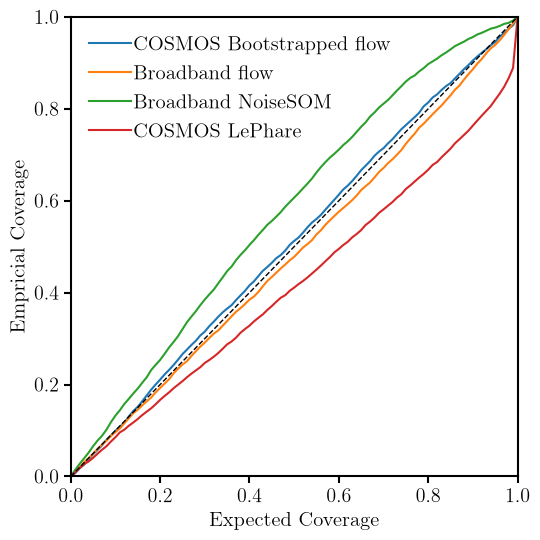

In [42]:
levels = np.linspace(0, 1, 101)
fig = plt.figure(figsize=(5.5,5.5))
sub = fig.add_subplot(111)
for key, label, color in models:
    pit = predictions[key]['pit']
    sub.plot(levels, coverage(pit, levels), label=label, color=color)

sub.plot([0, 1], [0, 1], 'k--', lw=1)
sub.set_xlabel('Expected Coverage', fontsize=15)
sub.set_ylabel('Empricial Coverage', fontsize=15)
sub.set(xlim=(0, 1), ylim=(0, 1))
sub.legend(fontsize=15, loc='upper left', handletextpad=0.1)
fig.tight_layout()
# fig.savefig(out_dir / 'calibration.png', dpi=180)
# if export_paper:
#     fig.savefig(paper_dir / 'fig03_calibration_notebook_comparison.pdf')
plt.show()